In [74]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LogNorm

import matplotlib as mpl

from scipy import interpolate
import scipy.optimize

from copy import deepcopy
import time
from tqdm import tqdm

from ngsolve import *
from ngsolve.webgui import Draw
from netgen.csg import *

from netgen.occ import *
from netgen.meshing import IdentificationType

# my functions
from helper_functions import *

## FINISH charge diff fct

* maybe the gfQ_dipole needs to be dipole_q/V_sphere?
* fix arguments of gen_charge and interpolate charge in charge diff fct

## UNITS

In [75]:
### unit-system: Angstrom = 1, eV = 1, e_charge = 1

### choices, see lammps metal system: https://docs.lammps.org/units.html

Angstrom = 1
eV = 1
e_charge = 1
Volt = 1

### independent

finestructure_constant = 0.0072973525643 # Finestructure constant, independent of unit-system   , https://en.wikipedia.org/wiki/Fine-structure_constant

### derived

hbar = 6.582119569 * pow(10.0, -4.0) ## eV * pico seconds, 1 pico second = 10^(-12) seconds

### units of time are in pico seconds, this implies units of velocity are in Angstrom / picoseconds

c_speed_of_light = 2.99792458 * pow(10.0, 6.0) ## Angstrom/pico seconds

pico_second = 1

nm = 10 ## 1nm = 10 Angstrom


hbar_times_c = 1973  # eV * Angstrom  # https://en.wikipedia.org/wiki/Planck_constant#Reduced_Planck_constant
h_times_c = 2.0 * np.pi * hbar_times_c

epsilon_0 = (e_charge * e_charge) / (2.0 * finestructure_constant * h_times_c)    # https://en.wikipedia.org/wiki/Vacuum_permittivity
mu_0 = 1.0 / (c_speed_of_light * epsilon_0)    # https://en.wikipedia.org/wiki/Vacuum_permeability
mu_0 /= c_speed_of_light ### don't divide by c^2 immediately

######################
######################
######################


### constants
a_lattice = 2.46

grapheneheight = 3.35 # Angstrom

blg_grapheneheight = grapheneheight ### see Jung & MacDonald PRB 89, 035405 (2014) #2.0 * grapheneheight

bilayer_graphene_area, bilayer_graphene_volume = blg_area_vol(a_lattice, blg_grapheneheight, Angstrom)
print(blg_grapheneheight)


3.35


### imports BLG iDOS

In [76]:
dummy_idos_shape = np.zeros(2, np.int64)


dos_folder = "new_ps_helper_functions/JungMacDonald_energy_range_m200meV_200meV_increment_0.5meV_U_range_0_200_meV_increment_0.5meV_VSC"

#dos_folder = "new_ps_helper_functions/JungMacDonald_energy_range_m200meV_200meV_increment_0.25meV_U_range_0_200_meV_increment_0.25meV_VSC"




### read arrays

idos = np.load(dos_folder+"/idos_blg.npy")
    
band_gaps = np.load(dos_folder+"/band_gap.npy")

displacement_field_intervals = np.load(dos_folder+"/displacementfield_intervalls.npy")

energy_interval = np.load(dos_folder+"/energy_intervall.npy")

### shapes


#dummy_idos_shape = read_idos.shape

## interpolate BLG iDOS

In [77]:
correct_prefactor = 1.0 / (bilayer_graphene_volume) ### this dos is already in units of 1/Energy, convert to density/Energy

idos = -idos * correct_prefactor


en_min = energy_interval[0] ## -0.2 eV
en_max = energy_interval[-1]  ## 0.2 eV

pot_min = displacement_field_intervals[0]  ## 0 eV
pot_max = displacement_field_intervals[-1] ## 0.2 eV


en_steps = idos.shape[1] 

e_incr = (en_max - en_min) / (en_steps - 1)

pot_steps = idos.shape[0] 

pot_incr = (pot_max - pot_min) / (pot_steps - 1)

en_intervall = np.linspace(en_min, en_max, en_steps)

en_incr = (en_max - en_min) / (en_steps - 1)

pot_intervall = np.linspace(pot_min, pot_max, pot_steps)

en_mesh, pot_mesh = np.meshgrid(en_intervall, pot_intervall)  # 2D grid for interpolation

begin_barycentricscipy_interpolation_time = time.time()

idos_interpolated = scipy.interpolate.LinearNDInterpolator(np.array([np.ravel(pot_mesh), np.ravel(en_mesh)]).T,
                                                           idos.reshape(pot_steps*en_steps))

end_barycentricscipy_interpolation_time = time.time()


print("interpolation took ", end_barycentricscipy_interpolation_time - begin_barycentricscipy_interpolation_time, " seconds")

interpolation took  2.989746332168579  seconds


## DIPOLE GEOMETRY

In [78]:
# dipole from two spheres in box
vac_box_width = 250
height_bottom = blg_grapheneheight * 4
height_top = blg_grapheneheight * 1.5
box_width = vac_box_width

hBn_bottom = Box(Pnt(0 ,0 ,0 ), Pnt(box_width, box_width, height_bottom))
BLG = Box(Pnt(0 ,0 , height_bottom), Pnt(box_width, box_width, height_bottom + blg_grapheneheight))
hBn_top = Box(Pnt(0 ,0 , height_bottom + blg_grapheneheight), Pnt(box_width, box_width, height_bottom + blg_grapheneheight + height_top))

hBn_bottom.mat("hBn")
BLG.mat("BLG")
hBn_top.mat("hBn")



dipole_moment_debye = 40

dipole_moment = 0.20819427 * dipole_moment_debye

benzen_a = 1.4 # Angstrom
benzen_diameter = 2 * benzen_a
dipole_position = 0.05 * vac_box_width


dipole_d = 3 * benzen_diameter # roughly the size of the molecule from the chemitry paper
dipole_q = dipole_moment/dipole_d
print("dipole seperation = ",dipole_d, "Angstom")
print("dipole charge = ",dipole_q, "e")

sphere_radius = 0.5 # radius should be as small as possible to imitate ideal dipol?
V_sphere = 4/3 * np.pi * sphere_radius ** 3

vac_origin = np.array([0.0, 0.0, height_bottom + blg_grapheneheight + height_top])
center_vec = vac_origin + np.array([0.5 * vac_box_width, 0.5 * vac_box_width, dipole_position])
sphere_center_vec = np.array([0.0, 0.5 * dipole_d, 0.0])
pos_sphere_center = center_vec + sphere_center_vec
neg_sphere_center = center_vec - sphere_center_vec

vac_box = Box(Pnt(vac_origin[0], vac_origin[1], vac_origin[2]), Pnt(vac_box_width, vac_box_width, vac_box_width + vac_origin[2]))
pos_sphere = Sphere(Pnt(pos_sphere_center[0], pos_sphere_center[1], pos_sphere_center[2]), sphere_radius)
neg_sphere = Sphere(Pnt(neg_sphere_center[0], neg_sphere_center[1], neg_sphere_center[2]), sphere_radius)

vac_box = vac_box - pos_sphere - neg_sphere

vac_box.mat("vac")
pos_sphere.mat("positive dipole")
neg_sphere.mat("negative dipole")

### boundaries names
hBn_bottom.faces.Min(Z).name = "bottom"
vac_box.faces.Max(Z).name = "top"

hBn_bottom.faces.Min(X).name = "bot_min_x"
hBn_bottom.faces.Max(X).name = "bot_max_x"
hBn_bottom.faces.Min(Y).name = "bot_min_y"
hBn_bottom.faces.Max(Y).name = "bot_max_y"

BLG.faces.Min(X).name = "blg_min_x"
BLG.faces.Max(X).name = "blg_max_x"
BLG.faces.Min(Y).name = "blg_min_y"
BLG.faces.Max(Y).name = "blg_max_y"

hBn_top.faces.Min(X).name = "top_min_x"
hBn_top.faces.Max(X).name = "top_max_x"
hBn_top.faces.Min(Y).name = "top_min_y"
hBn_top.faces.Max(Y).name = "top_max_y"

vac_box.faces.Min(X).name = "vac_min_x"
vac_box.faces.Max(X).name = "vac_max_x"
vac_box.faces.Min(Y).name = "vac_min_y"
vac_box.faces.Max(Y).name = "vac_max_y"
###

geo_dipole = OCCGeometry([vac_box, hBn_bottom, hBn_top, BLG, pos_sphere, neg_sphere])

mesh_dipole = Mesh(geo_dipole.GenerateMesh(maxh=box_width/5)).Curve(3) # what should I put for maxh argument of OCCgeometry.GeneraterMesh()??? maximale dreieckecksgröße

dipole_charges = {
    "positive dipole": dipole_q/V_sphere,
    "negative dipole": -1 * dipole_q/V_sphere,
    "vac": 0.0,
    "hBn": 0.0,
    "BLG": 0.0
}

cf_dipole = mesh_dipole.MaterialCF(dipole_charges, default=0)

fes_dipole = L2(mesh_dipole, order=3)#, definedon=mesh_dipole.Materials("positive dipole|negative dipole")) # use H1 or L2 here??? Draw with correct colors only works with H1 wtf
#fes_dipole_pos = H1(mesh_dipole, order=3, definedon="positive dipole")

gfQ_dipole = GridFunction(fes_dipole)
#gfQ_pos = GridFunction(fes_dipole_pos)

gfQ_dipole.Set(cf_dipole)
#gfQ_neg.Set(dipole_q, definedon="positive dipole")
#gfQ_pos.Set(dipole_q)

dipole seperation =  8.399999999999999 Angstom
dipole charge =  0.9914012857142859 e


In [79]:
Draw(gfQ_dipole)

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

BaseWebGuiScene

In [80]:
print("min:", min(gfQ_dipole.vec.FV().NumPy()))
print("max:", max(gfQ_dipole.vec.FV().NumPy()))

min: -1.8934369825090693
max: 1.8934369825090693


In [81]:
print(Integrate(gfQ_dipole, mesh_dipole.Materials("positive dipole|negative dipole")))
print(Integrate(gfQ_dipole, mesh_dipole.Materials("positive dipole")))

4.938507818137705e-08
0.991563055090753


In [82]:
print(mesh_dipole.GetMaterials())

('hBn', 'hBn', 'BLG', 'positive dipole', 'negative dipole', 'vac')


## Dielectric tensor

In [83]:
inplane_hBn_bulk = 4.98 ### see https://www.nature.com/articles/s41699-018-0050-x 
outofplane_hBn_bulk = 3.03

inplane_graphene = 1.8 ### https://pubs.acs.org/doi/10.1021/nl303611v
outofplane_graphene = 3
    
    
eps_dict = {"hBn" : CoefficientFunction((inplane_hBn_bulk, 0, 0,
                             0, inplane_hBn_bulk, 0,
                             0, 0, outofplane_hBn_bulk),dims=(3,3)),
                        "BLG" : CoefficientFunction((inplane_graphene, 0, 0,
                             0, inplane_graphene, 0,
                             0, 0, outofplane_graphene),dims=(3,3)),
                        "vac" : CoefficientFunction((1.0, 0, 0,
                             0, 1.0, 0,
                             0, 0, 1.0), dims=(3,3)),    
                        "positive dipole" : CoefficientFunction((1.0, 0, 0,
                             0, 1.0, 0,
                             0, 0, 1.0), dims=(3,3)),
                        "negative dipole" : CoefficientFunction((1.0, 0, 0,
                             0, 1.0, 0,
                             0, 0, 1.0), dims=(3,3))
                         }

## Solve once

In [84]:
bottom_bc = 0.05
top_bc = 0.0
other_bc = 0.0

bound_dict = {'bottom' : bottom_bc*Volt, 'top' : top_bc,
                'top_max_x' : other_bc, 'top_min_x' : other_bc, 'top_max_y' : other_bc, 'top_min_y' : other_bc,
                'bot_max_x' : other_bc, 'bot_min_x' : other_bc, 'bot_max_y' : other_bc, 'bot_min_y' : other_bc,
                'blg_max_x' : other_bc, 'blg_min_x' : other_bc, 'blg_max_y' : other_bc, 'blg_min_y' : other_bc,
                'vac_max_x' : other_bc, 'vac_min_x' : other_bc, 'vac_max_y' : other_bc, 'vac_min_y' : other_bc
              }

fes = H1(mesh_dipole, order=2, dirichlet="bottom|top|top_max_x|top_min_x|top_max_y|top_min_y|bot_max_x|bot_min_x|bot_max_y|bot_min_y|blg_max_x|blg_min_x|blg_max_y|blg_min_y|vac_max_x|vac_min_x|vac_max_y|vac_min_y")
#print ("ndof=", fes.ndof)

epsr = mesh_dipole.MaterialCF( eps_dict )

u, v = fes.TnT() # TnT: test and trial
a = BilinearForm(epsilon_0 * epsr * grad(u) * grad(v) * dx)

#gfQ_dipole.Set(-0.0001)
f = LinearForm(gfQ_dipole * v * dx("positive dipole|negative dipole")).Assemble()
#f = LinearForm(fes)
#f += gfQ_dipole * v * dx

a.Assemble()


gfu  = GridFunction(fes) # gfu: grid function u; potential
# first way to define boundary conditions
gfud = mesh_dipole.BoundaryCF(bound_dict, default=0)
gfu.Set(gfud, BND)

# second option to define boundary conditions
#gfu.Set(0, definedon=mesh_dipole.Boundaries(".*"))
#gfu.Set(bottom_bc, definedon=mesh_dipole.Boundaries("bottom"))

inv = a.mat.Inverse(freedofs=fes.FreeDofs(), inverse="sparsecholesky")


res = (a.mat * gfu.vec - f.vec).Evaluate() # with dipole
#res = (a.mat * gfu.vec).Evaluate() # without dipole

gfu.vec.data -= inv * res


#Draw(gfu)

In [85]:
# evaluate gfu on the diagonal or straight up in z-direction
diagonal_vec = np.array([vac_box_width, vac_box_width, height_bottom + blg_grapheneheight + height_top + vac_box_width])
diagonal = np.linalg.norm(diagonal_vec)
diagonal_unit_vec = diagonal_vec/diagonal

starting_point = np.array([0.45 * vac_box_width, 0.45 * vac_box_width, 0])

#rs = np.linspace(0, diagonal, 400)
rs = np.linspace(0, blg_grapheneheight + vac_box_width + height_bottom + height_top, 400)

gfu_values = []

for r in rs:
    #print(r)
    p = starting_point + r * np.array([0,0,1]) #diagonal_unit_vec
    gfu_values.append(gfu(mesh_dipole(*p)))

Text(0, 0.5, '$\\phi(z)$')

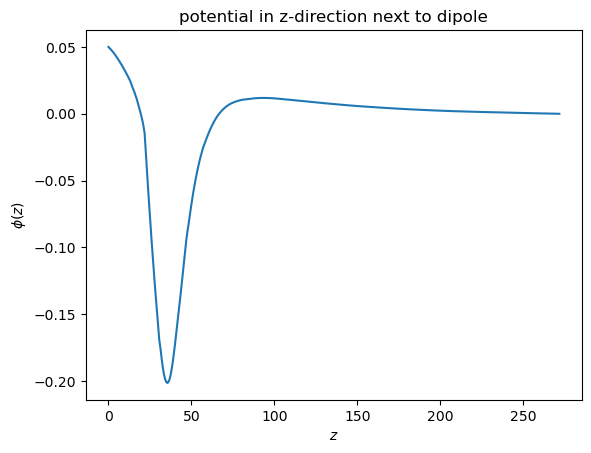

In [86]:
plt.plot(rs[:], gfu_values[:])
plt.title("potential in z-direction next to dipole")
plt.xlabel('$z$')
plt.ylabel('$\\phi(z)$')

In [87]:
print(np.min(gfu_values))

-0.20129994839311902


In [88]:
print(f'not vac height: {height_bottom + height_top + blg_grapheneheight}')
print(f'vac height: {vac_box_width}')

not vac height: 21.775000000000002
vac height: 250


In [89]:
z0 = height_bottom + 0.5 * blg_grapheneheight  # your slice height

nx = 200
ny = 200

x_vals = np.linspace(0, vac_box_width, nx)
y_vals = np.linspace(0, vac_box_width, ny)

phi_slice = np.zeros((ny, nx))


X, Y = np.meshgrid(x_vals, y_vals)

pts = [(x, y, z0) for x, y in zip(X.ravel(), Y.ravel())]

vals = [gfu(mesh_dipole(*p)) for p in pts]

phi_slice = np.array(vals).reshape(ny, nx)

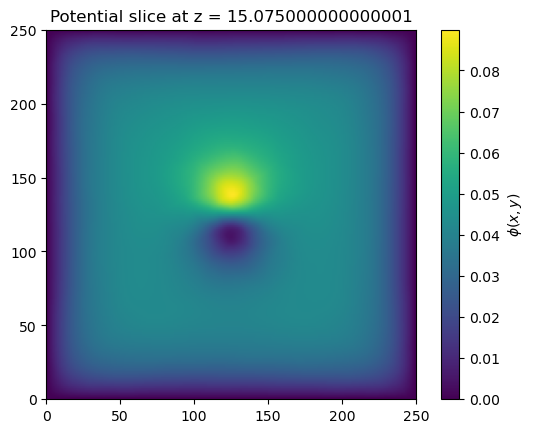

In [90]:
plt.imshow(
    phi_slice,
    extent=[0, box_width, 0, box_width],
    origin="lower",
    aspect="equal"
)
plt.colorbar(label="$\phi(x,y)$")
plt.title(f"Potential slice at z = {z0}")
plt.show()

In [91]:
print(gfu.space.ndof)
print(gfQ_dipole.space.ndof)

19955
281300


In [92]:
### core poisson solver iteration

# add boundary conditions for gfu and gfQ_dipole here!!!!!

def residual_of_charge(charge, show_plots = False):
    
    a = a_vec[0] # triviale liste, ein element, inverse 

    charge = charge.reshape((fem_n, fem_n))
    

    u, v = fes.TnT()

    # new arguments: hBn_thickness, edge_length, blg, thickness
    interpolate_charge(charge, gfQ, hBn_thickness, edge_length, blg_thickness)
    
    #update right side of poisson equation
    with TaskManager():
        
        #f   = LinearForm( gfQ * v * dx("bilayer_graphene")).Assemble() # old version for f
        # new f with gfQ<_dipole: 
        f = LinearForm(fes)
        f += gfQ_dipole * v * dx("positive dipole|negative dipole")
        f += gfQ * v * dx("BLG")
        f.Assemble()

        gfu.Set(gfud, BND)
    

        res = (a.mat * gfu.vec - f.vec).Evaluate()
        gfu.vec.data -= inv * res

    # new arguments: fem_n, meshptsTop, meshptsBot, pot_min, pot_max, en_min, en_max, idos_interpolated
    new_charge, new_average_pot, new_diff_pot = gen_charge(gfu, fem_n, meshptsTop, meshptsBot, pot_min, pot_max, en_min, en_max, idos_interpolated)

    
    n_it = global_it[0]
    
    global_it[0] = global_it[0] + 1


    if show_plots == True:
    
        #plot figures
        plt.figure(figsize=(11,8))
        gs=gridspec.GridSpec(1,4, wspace = 0.6) 
        ax = plt.subplot(gs[0,0])
        img = ax.imshow(charge*pow(nm,3), origin="lower")
        plt.colorbar(img, ax=ax,fraction=0.046, pad=0.04)
        ax2 = plt.subplot(gs[0,1])
        img2 = ax2.imshow(new_charge*pow(nm,3), origin="lower")
        plt.colorbar(img2, ax=ax2,fraction=0.046, pad=0.04)
        ax3 = plt.subplot(gs[0,2])
        img3 = ax3.imshow((charge - new_charge) * pow(nm,3), origin="lower")
        plt.colorbar(img3, ax=ax3,fraction=0.046, pad=0.04)
        ax4 = plt.subplot(gs[0,3])
        img4 = ax4.imshow(new_average_pot, origin="lower")
        plt.colorbar(img4, ax=ax4,fraction=0.046, pad=0.04)
        plt.suptitle("iteration " + str(n_it) + "  "+  r" $\rho_{old}$" + " , " +\
                 r" $\rho_{new}$" + " , " + r" $\Delta\rho$ and" +\
                 r" $\phi_{new}$", y=0.7)
        plt.show()

    
    

    

    history_charges[0] = [new_charge]
    history_pots_avg[0] = [new_average_pot]
    history_diff_pot[0] = [new_diff_pot]

    integrated_charge = blg_grapheneheight*np.trapezoid(np.trapezoid(charge, dx=increment), dx=increment)
    integrated_new_charge = blg_grapheneheight*np.trapezoid(np.trapezoid(new_charge, dx=increment), dx=increment)

    charge = np.ravel(charge)

    new_charge = np.ravel(new_charge)
    
    print("#", n_it, "  rho_n-1 - rho_n (max): ", np.max(abs(charge - new_charge)))
    print("#", n_it, "  |q_n-1 - q_n| : ", abs(integrated_charge - integrated_new_charge))
    return  (charge - new_charge)

In [93]:
fem_n = 100
edge_length = vac_box_width
hBn_thickness = height_bottom
epsilon_z = 1e-4
blg_thickness = blg_grapheneheight


In [94]:
#### defining chessboard on model

## mesh points

if 1:
    
    
    increment = edge_length / (fem_n - 1)
    
    xs   = np.linspace(0, edge_length, fem_n)
    ys   = np.linspace(0, edge_length, fem_n)

    zs_Bot = np.array(hBn_thickness + epsilon_z)

    zs_Mid = np.array(hBn_thickness + blg_thickness/2)

    zs_Top = np.array(hBn_thickness + blg_thickness - epsilon_z)

    dummy_m_x, dummy_m_y, dummy_m_z_b = np.meshgrid(xs, ys, zs_Bot)
    
    dummy_m_z_m = np.ones((fem_n,fem_n,1), dtype=np.float64) * zs_Mid
    dummy_m_z_t = np.ones((fem_n,fem_n,1), dtype=np.float64) * zs_Top
    
    ptsBot = np.array([np.ravel(dummy_m_x), np.ravel(dummy_m_y), np.ravel(dummy_m_z_b)]).T
    
    ptsMid = np.array([np.ravel(dummy_m_x), np.ravel(dummy_m_y), np.ravel(dummy_m_z_m)]).T

    ptsTop = np.array([np.ravel(dummy_m_x), np.ravel(dummy_m_y), np.ravel(dummy_m_z_t)]).T
            
    meshptsTop = mesh_dipole(ptsTop[:,0], ptsTop[:,1], ptsTop[:,2])
    meshptsMid = mesh_dipole(ptsMid[:,0], ptsMid[:,1], ptsMid[:,2])
    meshptsBot = mesh_dipole(ptsBot[:,0], ptsBot[:,1], ptsBot[:,2])

In [95]:
from helper_functions import *

In [96]:
#### cycle
# solve homogeneous problem
fesQ = L2(mesh_dipole, order=3, definedon="BLG")
gfQ = GridFunction(fesQ)

u, v = fes.TnT()
a = BilinearForm(epsilon_0 * epsr * grad(u) * grad(v) * dx).Assemble() 

gfu  = GridFunction(fes)
gfud = mesh_dipole.BoundaryCF( bound_dict, default=0)
gfu.Set(gfud, BND)

inv = a.mat.Inverse(freedofs=fes.FreeDofs(), inverse="sparsecholesky")

f = LinearForm(gfQ_dipole * v * dx("positive dipole|negative dipole")).Assemble()

res = (a.mat * gfu.vec - f.vec).Evaluate()

gfu.vec.data -= inv * res

# use homogenous solution as starting point
gfu_solveonce  = GridFunction(fes)
gfu_solveonce.Set(gfu)


charge, average_pot, diff_pot = gen_charge(gfu, fem_n, meshptsTop, meshptsBot, pot_min, pot_max, en_min, en_max, idos_interpolated, alpha = 0.01) #0.01 #0.00001 #0.00001



global global_it
global history_charges
global history_pots_av
global history_pots_diff
global a_vec
global_it = [0]

history_charges = [charge]
history_pots_avg = [average_pot]
history_diff_pot = [diff_pot]

a_vec = [a]


charge = np.ravel(charge)


start_time = time.time()

sol = scipy.optimize.root(residual_of_charge, 
                charge,  args=(False),
                method='df-sane', options = {"fatol": pow(10,-9)})  # -9

end_time = time.time()

print("solver takes ", end_time - start_time, " seconds and ", global_it[0], " iterations")

print("charge =", Integrate(gfQ, mesh_dipole, definedon=mesh_dipole.Materials("BLG")))

# 0   rho_n-1 - rho_n (max):  0.00010765389010427049
# 0   |q_n-1 - q_n| :  7.226821910465309
# 1   rho_n-1 - rho_n (max):  0.0002679267562724917
# 1   |q_n-1 - q_n| :  22.27953911821926
# 2   rho_n-1 - rho_n (max):  0.00041211374118685086
# 2   |q_n-1 - q_n| :  38.37183979624215
# 3   rho_n-1 - rho_n (max):  7.11782609777433e-05
# 3   |q_n-1 - q_n| :  4.54949946083319
# 4   rho_n-1 - rho_n (max):  2.1177132213790372e-05
# 4   |q_n-1 - q_n| :  0.3177776901674434
# 5   rho_n-1 - rho_n (max):  8.889180668853609e-06
# 5   |q_n-1 - q_n| :  0.0662773288694134
# 6   rho_n-1 - rho_n (max):  3.293625811549595e-06
# 6   |q_n-1 - q_n| :  0.0019207124233475703
# 7   rho_n-1 - rho_n (max):  1.5732327948496943e-06
# 7   |q_n-1 - q_n| :  0.0021870431410486724
# 8   rho_n-1 - rho_n (max):  7.901575054360648e-07
# 8   |q_n-1 - q_n| :  0.0022503031366509774
# 9   rho_n-1 - rho_n (max):  7.151050430161791e-07
# 9   |q_n-1 - q_n| :  0.003306639907167064
# 10   rho_n-1 - rho_n (max):  3.602265735335597e-0

In [97]:
Integrate(gfQ, mesh_dipole, definedon=mesh_dipole.Materials("BLG"))

-2.0826715194030196

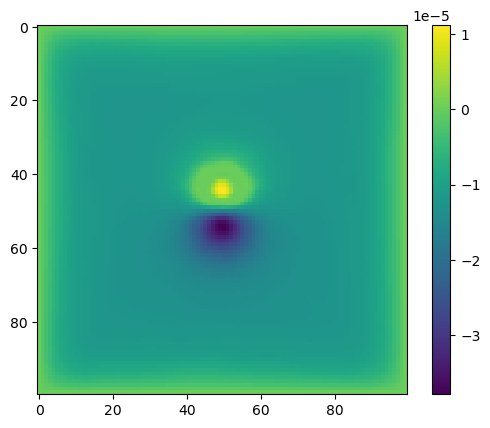

In [98]:
plt.imshow(gfQ(meshptsMid).reshape((fem_n, fem_n)))
plt.colorbar()
plt.show()

In [99]:
gfQ(meshptsMid).reshape((fem_n, fem_n))

array([[-1.84881016e-10, -1.36307985e-10,  1.52550781e-09, ...,
         6.66205593e-09, -3.72381410e-10, -5.39296497e-10],
       [ 1.41946920e-10, -3.20371820e-07, -5.56886869e-07, ...,
        -6.91363330e-07, -4.21964973e-07,  7.01595809e-14],
       [ 2.07948267e-09, -5.56091676e-07, -9.98236233e-07, ...,
        -1.24645110e-06, -6.63608812e-07,  2.44870786e-09],
       ...,
       [ 1.00957861e-09, -5.82104024e-07, -1.02997231e-06, ...,
        -9.58609864e-07, -5.35457916e-07,  5.04742525e-09],
       [-1.40518652e-09, -3.25352326e-07, -5.76324923e-07, ...,
        -5.50233407e-07, -3.23921257e-07, -5.04838920e-10],
       [-3.02997979e-09, -4.40924524e-10, -6.85629185e-10, ...,
         6.22056660e-09, -5.67214201e-10, -6.35627672e-10]],
      shape=(100, 100))

In [1]:
18.8972613 * 0.1

1.8897261300000001

In [2]:
18.8972613 * 5

94.4863065

In [3]:
1.88972613 * 5

9.44863065